# Assignment 2: Convolutional Neural Networks (CNN)

This notebook covers all three parts of the assignment:

1. **Practice: CNN Architecture** – implement the specified CNN in PyTorch.
2. **Practice: Model Deployment** – train the CNN on CIFAR-10 and serve it through the FastAPI app (`api/main.py`).
3. **Theory: Arithmetic of CNNs** – answers to Questions 1–6 with all work shown.

GitHub repository: https://github.com/yuchienchen0930/5560-api-project

In [1]:
import os
# Anaconda and PyTorch each ship their own OpenMP runtime (libiomp5md.dll), which crashes
# the kernel (OMP Error #15) when matplotlib is used. Must be set before importing torch.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import inspect
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt
import numpy as np

from model.cnn_model import AssignmentCNN
from model.cifar_data import CIFAR10Parquet, CLASSES

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## Part 1: CNN Architecture

Required architecture:

| # | Layer | Output shape (H × W × C) |
|---|-------|--------------------------|
| 0 | Input: RGB image | 64 × 64 × 3 |
| 1 | Conv2D, 16 filters, 3×3, stride 1, padding 1 + ReLU | 64 × 64 × 16 |
| 2 | MaxPool2D, 2×2, stride 2 | 32 × 32 × 16 |
| 3 | Conv2D, 32 filters, 3×3, stride 1, padding 1 + ReLU | 32 × 32 × 32 |
| 4 | MaxPool2D, 2×2, stride 2 | 16 × 16 × 32 |
| 5 | Flatten | 8192 |
| 6 | Fully connected, 100 units + ReLU | 100 |
| 7 | Fully connected, 10 units | 10 |

**Output size of each layer** uses $\text{out} = \left\lfloor \frac{W + 2P - K}{S} \right\rfloor + 1$:

- Conv1: $(64 + 2\cdot1 - 3)/1 + 1 = 64$ → 64 × 64 × 16
- Pool1: $(64 - 2)/2 + 1 = 32$ → 32 × 32 × 16
- Conv2: $(32 + 2\cdot1 - 3)/1 + 1 = 32$ → 32 × 32 × 32
- Pool2: $(32 - 2)/2 + 1 = 16$ → 16 × 16 × 32
- Flatten: $16 \times 16 \times 32 = 8192$

**Number of trainable parameters** (weights + biases):

- Conv1: $3 \times 3 \times 3 \times 16 + 16 = 448$
- Conv2: $3 \times 3 \times 16 \times 32 + 32 = 4{,}640$
- FC1: $8192 \times 100 + 100 = 819{,}300$
- FC2: $100 \times 10 + 10 = 1{,}010$
- **Total: 825,398**

The model is defined in `model/cnn_model.py` so that the API can import the same class:

In [2]:
print(inspect.getsource(AssignmentCNN))

class AssignmentCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(AssignmentCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1)   # 64x64x3  -> 64x64x16
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)                  # 64x64x16 -> 32x32x16

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)  # 32x32x16 -> 32x32x32
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)                  # 32x32x32 -> 16x16x32

        self.fc1 = nn.Linear(32 * 16 * 16, 100)                             # 8192 -> 100
        self.fc2 = nn.Linear(100, num_classes)                              # 100 -> 10

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x



In [3]:
model = AssignmentCNN(num_classes=10).to(device)
print(model)

# Trace a dummy 64x64 RGB image through the network to verify every layer's output shape
x = torch.randn(1, 3, 64, 64).to(device)
print("\nInput:          ", tuple(x.shape))
x = torch.relu(model.conv1(x)); print("Conv1 + ReLU:   ", tuple(x.shape))
x = model.pool1(x);             print("MaxPool1:       ", tuple(x.shape))
x = torch.relu(model.conv2(x)); print("Conv2 + ReLU:   ", tuple(x.shape))
x = model.pool2(x);             print("MaxPool2:       ", tuple(x.shape))
x = torch.flatten(x, 1);        print("Flatten:        ", tuple(x.shape))
x = torch.relu(model.fc1(x));   print("FC1 + ReLU:     ", tuple(x.shape))
x = model.fc2(x);               print("FC2 (output):   ", tuple(x.shape))

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal trainable parameters: {total_params:,}")

AssignmentCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=8192, out_features=100, bias=True)
  (fc2): Linear(in_features=100, out_features=10, bias=True)
)

Input:           (1, 3, 64, 64)
Conv1 + ReLU:    (1, 16, 64, 64)
MaxPool1:        (1, 16, 32, 32)
Conv2 + ReLU:    (1, 32, 32, 32)
MaxPool2:        (1, 32, 16, 16)
Flatten:         (1, 8192)
FC1 + ReLU:      (1, 100)
FC2 (output):    (1, 10)

Total trainable parameters: 825,398


## Part 2: Model Deployment

### 2.1 Load CIFAR-10

CIFAR-10 contains 60,000 32×32 colour images in 10 classes (50,000 train / 10,000 test).
Because the architecture expects **64×64×3** input, every image is resized to 64×64.
Random horizontal flips are used as light data augmentation on the training set, and pixels are normalized to $[-1, 1]$.

The data is the official CIFAR-10 release (`uoft-cs/cifar10`) loaded from Parquet files; it is identical to
`torchvision.datasets.CIFAR10` (same images, labels and class order), which can be swapped in directly.

In [4]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_dataset = CIFAR10Parquet("data/cifar10", train=True, transform=train_transform)
test_dataset = CIFAR10Parquet("data/cifar10", train=False, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

print("Train images:", len(train_dataset), "| Test images:", len(test_dataset))
print("Classes:", CLASSES)
print("Image tensor shape:", tuple(train_dataset[0][0].shape))

Train images: 50000 | Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Image tensor shape: (3, 64, 64)


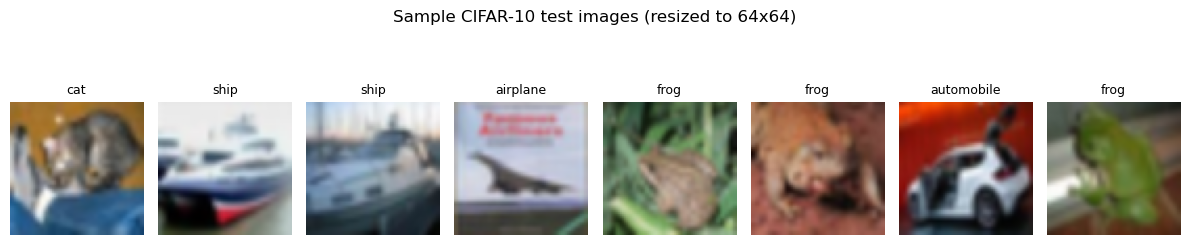

In [5]:
def denormalize(img):
    return (img * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()

plt.figure(figsize=(12, 3))
for i in range(8):
    img, label = test_dataset[i]
    plt.subplot(1, 8, i + 1)
    plt.imshow(denormalize(img))
    plt.title(CLASSES[label], fontsize=9)
    plt.axis("off")
plt.suptitle("Sample CIFAR-10 test images (resized to 64x64)")
plt.tight_layout()
plt.show()

### 2.2 Train the model

Loss: cross-entropy. Optimizer: Adam (learning rate 0.001). 10 epochs.
`model.train()` is called at the start of every epoch because `evaluate()` switches the model to `model.eval()` (see Question 6).

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            all_preds.append(preds.cpu())
            all_labels.append(labels.cpu())
    return total_loss / total, correct / total, torch.cat(all_preds), torch.cat(all_labels)

epochs = 10
history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
for epoch in range(epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    test_loss, test_acc, _, _ = evaluate(model, test_loader)
    for k, v in zip(history, (train_loss, train_acc, test_loss, test_acc)):
        history[k].append(v)
    print(f"Epoch {epoch+1:2d}/{epochs} | train loss {train_loss:.4f} acc {train_acc:.4f} "
          f"| test loss {test_loss:.4f} acc {test_acc:.4f}")

Epoch  1/10 | train loss 1.4236 acc 0.4888 | test loss 1.2023 acc 0.5669


Epoch  2/10 | train loss 1.1221 acc 0.6008 | test loss 1.0890 acc 0.6096


Epoch  3/10 | train loss 0.9943 acc 0.6487 | test loss 1.0561 acc 0.6315


Epoch  4/10 | train loss 0.9031 acc 0.6824 | test loss 0.9925 acc 0.6490


Epoch  5/10 | train loss 0.8287 acc 0.7095 | test loss 0.9690 acc 0.6628


Epoch  6/10 | train loss 0.7605 acc 0.7326 | test loss 0.9066 acc 0.6823


Epoch  7/10 | train loss 0.7057 acc 0.7522 | test loss 0.9380 acc 0.6834


Epoch  8/10 | train loss 0.6506 acc 0.7719 | test loss 0.9109 acc 0.6956


Epoch  9/10 | train loss 0.6065 acc 0.7877 | test loss 0.9592 acc 0.6836


Epoch 10/10 | train loss 0.5595 acc 0.8073 | test loss 0.9650 acc 0.6895


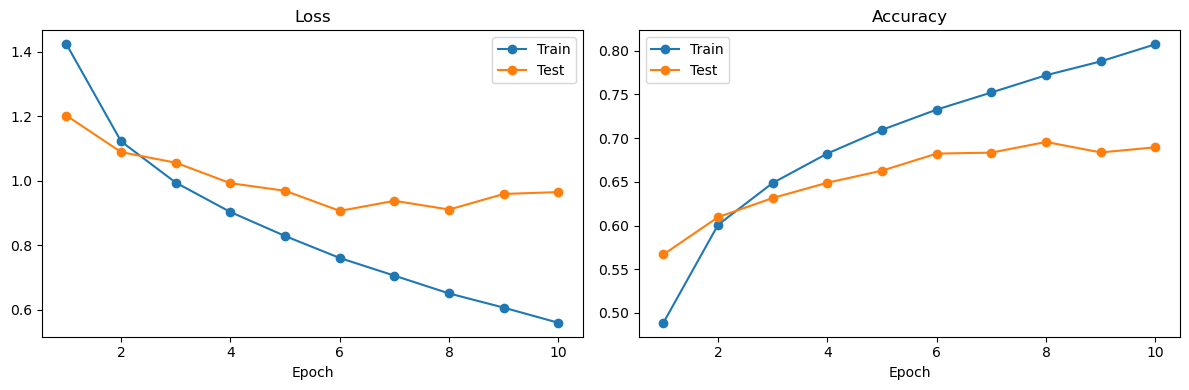

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ep = range(1, epochs + 1)
axes[0].plot(ep, history["train_loss"], marker="o", label="Train")
axes[0].plot(ep, history["test_loss"], marker="o", label="Test")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(ep, history["train_acc"], marker="o", label="Train")
axes[1].plot(ep, history["test_acc"], marker="o", label="Test")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

### 2.3 Evaluate on the test set

Final test accuracy: 0.6895

              precision    recall  f1-score   support

    airplane      0.758     0.726     0.742      1000
  automobile      0.840     0.732     0.782      1000
        bird      0.674     0.496     0.571      1000
         cat      0.433     0.635     0.515      1000
        deer      0.648     0.615     0.631      1000
         dog      0.618     0.557     0.586      1000
        frog      0.727     0.789     0.756      1000
       horse      0.792     0.727     0.758      1000
        ship      0.800     0.818     0.809      1000
       truck      0.732     0.800     0.764      1000

    accuracy                          0.690     10000
   macro avg      0.702     0.690     0.692     10000
weighted avg      0.702     0.690     0.692     10000



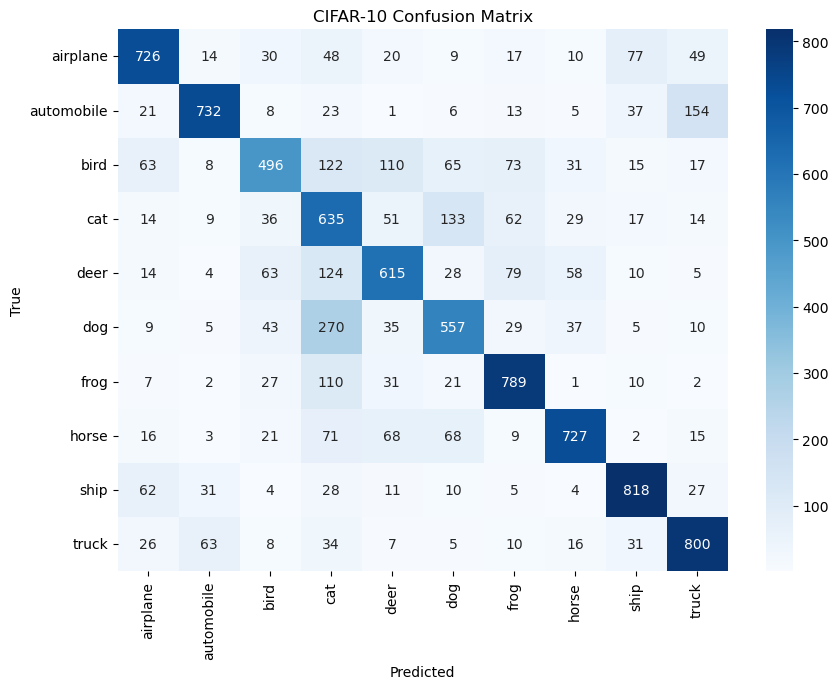

In [8]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

test_loss, test_acc, preds, labels = evaluate(model, test_loader)
print(f"Final test accuracy: {test_acc:.4f}\n")
print(classification_report(labels, preds, target_names=CLASSES, digits=3))

cm = confusion_matrix(labels, preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("CIFAR-10 Confusion Matrix")
plt.tight_layout()
plt.show()

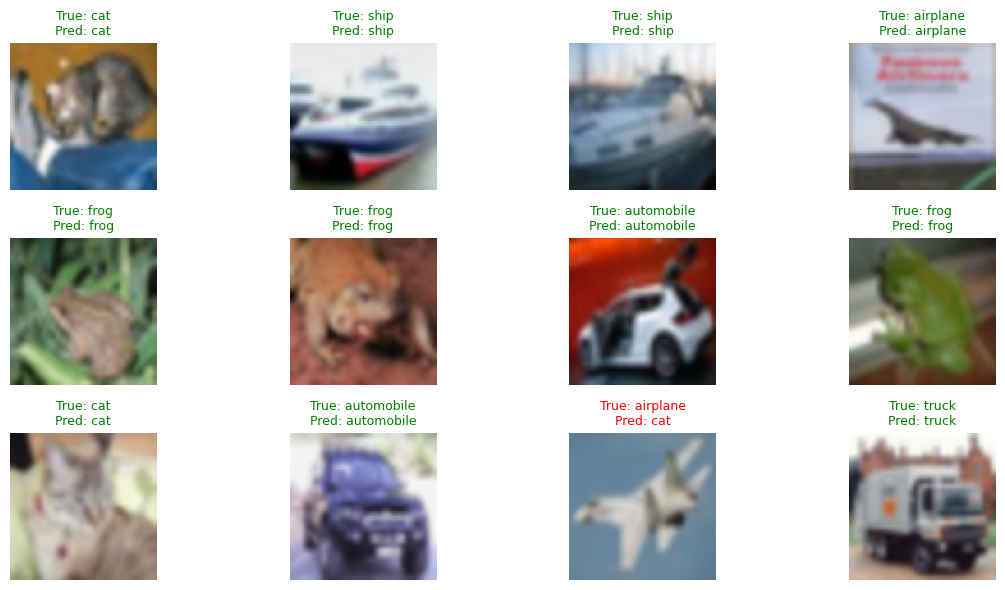

In [9]:
model.eval()
images, true_labels = next(iter(test_loader))
with torch.no_grad():
    pred_labels = model(images.to(device)).argmax(1).cpu()

plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(denormalize(images[i]))
    ok = pred_labels[i] == true_labels[i]
    plt.title(f"True: {CLASSES[true_labels[i]]}\nPred: {CLASSES[pred_labels[i]]}",
              color="green" if ok else "red", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

### 2.4 Save the model for the API

In [10]:
torch.save(model.state_dict(), "model/cifar10_cnn.pth")
print("Saved model weights to model/cifar10_cnn.pth")

Saved model weights to model/cifar10_cnn.pth


### 2.5 Serve the classifier with FastAPI

The API in `api/main.py` loads `model/cifar10_cnn.pth` and applies the same preprocessing as the test set
(resize to 64×64, normalize). Start it from the project root:

```
python -m uvicorn api.main:app --reload
```

| Method | Endpoint | Input | Output |
|--------|----------|-------|--------|
| GET | `/` | – | health check |
| GET | `/classes` | – | list of the 10 CIFAR-10 classes |
| POST | `/predict` | image file (form field `file`) | predicted class, class index, confidence, top-3 |
| POST | `/predict-digit` | image file | MNIST digit (earlier class activity) |

Example request:

```
curl -X POST -F "file=@cat.png" http://127.0.0.1:8000/predict
```

The interactive docs at http://127.0.0.1:8000/docs can also be used to upload an image.
The cell below calls the API code in-process to show that it returns the class of an input image.

In [11]:
import io
from fastapi.testclient import TestClient
from api.main import app

client = TestClient(app)
print("GET / ->", client.get("/").json())

for i in range(5):
    img, label = test_dataset.images[i], test_dataset.labels[i]
    buf = io.BytesIO(); img.save(buf, format="PNG"); buf.seek(0)
    resp = client.post("/predict", files={"file": (f"test_{i}.png", buf, "image/png")}).json()
    print(f"true={CLASSES[label]:<10} -> API: {resp['prediction']:<10} (confidence {resp['confidence']:.3f})")

GET / -> {'message': 'CNN Image Classifier API is running'}
true=cat        -> API: cat        (confidence 0.969)
true=ship       -> API: ship       (confidence 0.998)
true=ship       -> API: ship       (confidence 0.622)
true=airplane   -> API: airplane   (confidence 0.756)
true=frog       -> API: frog       (confidence 0.934)


C:\Users\User\anaconda3\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


## Part 3: Theory – Arithmetic of CNNs

For a convolution or pooling layer with input width $W$, kernel size $K$, padding $P$ and stride $S$:

$$
W_{out} = \left\lfloor \frac{W + 2P - K}{S} \right\rfloor + 1
$$

The output depth of a convolution equals the **number of filters**; pooling keeps the depth unchanged.

### Question 1
*Input 32×32×3, convolutional layer with 8 filters of size 5×5, stride 1, no padding.*

$$
W_{out} = \frac{32 + 2(0) - 5}{1} + 1 = 27 + 1 = 28
$$

Height is computed the same way (28). The depth is the number of filters (8); each 5×5 filter spans all 3 input channels (5×5×3) and produces one feature map.

**Answer: 28 × 28 × 8**

### Question 2
*Same layer, but padding is changed to "same".*

"Same" padding pads the input so that, with stride 1, the output has the same spatial size as the input.
For $K = 5$: $P = \frac{K - 1}{2} = \frac{5 - 1}{2} = 2$.

$$
W_{out} = \frac{32 + 2(2) - 5}{1} + 1 = 31 + 1 = 32
$$

**Answer: 32 × 32 × 8.** The spatial size grows from 28 × 28 to 32 × 32 (it now matches the input), while the depth stays at 8 because the number of filters does not change.

### Question 3
*3×3 filter, stride 2, no padding, 64×64 input.*

$$
W_{out} = \left\lfloor \frac{64 + 2(0) - 3}{2} \right\rfloor + 1 = \lfloor 30.5 \rfloor + 1 = 30 + 1 = 31
$$

The floor is needed because $(64 - 3)/2$ is not an integer. The filter's top-left corner can sit at positions 0, 2, 4, …, 60, which is 31 positions. At position 62 it would need pixels 62–64, but the last pixel is 63, so that window is dropped.

**Answer: 31 × 31**

### Question 4
*Max pooling 2×2, stride 2, on a 16×16 feature map.*

$$
W_{out} = \frac{16 + 2(0) - 2}{2} + 1 = 7 + 1 = 8
$$

**Answer: 8 × 8** (the number of channels is unchanged; pooling halves the height and width).

### Question 5
*128×128 image, two successive conv layers, each 3×3 kernel, stride 1, "same" padding.*

"Same" padding with $K = 3$ means $P = 1$.

- Layer 1: $\frac{128 + 2(1) - 3}{1} + 1 = 128$ → 128 × 128
- Layer 2: $\frac{128 + 2(1) - 3}{1} + 1 = 128$ → 128 × 128

**Answer: 128 × 128** spatially. "Same" padding with stride 1 preserves height and width at every layer, no matter how many layers are stacked. The depth equals the number of filters in the second layer (e.g. 128 × 128 × $F_2$).

### Question 6
*What happens if you remove `model.train()` before the training loop?*

`model.train()` does **not** run the training. It sets the module (and all of its sub-modules) to *training mode* (`model.training = True`). The mode only changes the behaviour of layers that act differently during training and inference:

- **Dropout**: in training mode it randomly zeroes activations; in eval mode it is disabled.
- **Batch Normalization**: in training mode it normalizes with the current mini-batch statistics and updates its running mean/variance; in eval mode it uses the stored running statistics and does not update them.

What happens when the line is removed depends on the model's current mode:

1. **A freshly created model is already in training mode** (PyTorch's default), so if `model.eval()` was never called, removing `model.train()` changes nothing.
2. **If `model.eval()` was called earlier** (for example, evaluating on the test set after each epoch, as in this notebook, or after loading a saved model), the model stays in eval mode during training. The loop still runs and the weights are still updated by backpropagation, but:
   - Dropout is turned off, so the model loses that regularization and is more likely to overfit.
   - BatchNorm uses fixed running statistics and stops updating them, so the normalization does not adapt to the data. Training can become slower or unstable, and test accuracy usually drops.
3. **For a model with no Dropout or BatchNorm** (such as the architecture in Part 1), training and eval mode behave identically, so removing the line would give the same results. It is still good practice to call `model.train()` so the code stays correct if such layers are added later.

In short, removing `model.train()` does not cause an error. It can silently make the model train in inference mode, which disables Dropout and freezes BatchNorm statistics.

### Verifying the answers with PyTorch

In [12]:
import torch.nn as nn

def shape(layer, x):
    return tuple(layer(x).shape[1:])  # (C, H, W)

print("Q1:", shape(nn.Conv2d(3, 8, kernel_size=5, stride=1, padding=0), torch.randn(1, 3, 32, 32)), "-> 28x28x8")
print("Q2:", shape(nn.Conv2d(3, 8, kernel_size=5, stride=1, padding="same"), torch.randn(1, 3, 32, 32)), "-> 32x32x8")
print("Q3:", shape(nn.Conv2d(1, 1, kernel_size=3, stride=2, padding=0), torch.randn(1, 1, 64, 64)), "-> 31x31")
print("Q4:", shape(nn.MaxPool2d(kernel_size=2, stride=2), torch.randn(1, 1, 16, 16)), "-> 8x8")
two_convs = nn.Sequential(nn.Conv2d(3, 16, 3, stride=1, padding="same"), nn.Conv2d(16, 16, 3, stride=1, padding="same"))
print("Q5:", shape(two_convs, torch.randn(1, 3, 128, 128)), "-> 128x128")

# Q6: train/eval mode only affects layers such as Dropout and BatchNorm
demo = nn.Sequential(nn.Linear(4, 4), nn.Dropout(0.5))
demo.eval()
print("\nQ6: after model.eval(), training mode =", demo.training)
x = torch.ones(1, 4)
print("    eval mode output (deterministic):", demo(x).detach().numpy().round(3))
demo.train()
print("    after model.train(), training mode =", demo.training)
print("    train mode output (dropout zeroes some values):", demo(x).detach().numpy().round(3))

Q1: (8, 28, 28) -> 28x28x8
Q2: (8, 32, 32) -> 32x32x8
Q3: (1, 31, 31) -> 31x31
Q4: (1, 8, 8) -> 8x8
Q5: (16, 128, 128) -> 128x128

Q6: after model.eval(), training mode = False
    eval mode output (deterministic): [[-0.091 -0.781 -0.467 -0.369]]
    after model.train(), training mode = True
    train mode output (dropout zeroes some values): [[-0.    -1.563 -0.934 -0.737]]


## Summary

- **Part 1:** `AssignmentCNN` implements the specified architecture exactly (64×64×3 input → 16 filters → pool → 32 filters → pool → FC 100 → FC 10), with 825,398 trainable parameters.
- **Part 2:** The model was trained on CIFAR-10 (images resized to 64×64) and served through the FastAPI `/predict` endpoint, which returns the predicted class of an uploaded image. The code is committed to GitHub.
- **Part 3:** Q1 28×28×8 · Q2 32×32×8 · Q3 31×31 · Q4 8×8 · Q5 128×128 · Q6 the model may be left in eval mode, which disables Dropout and freezes BatchNorm statistics during training.